In [48]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import platform
import scipy
import sklearn
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # Mandatory line
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    classification_report,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    PolynomialFeatures,
    SplineTransformer,
    StandardScaler,
)

RANDOM_STATE = 101126

The QSAR Bioconcentration Classes dataset contains manually curated fish bioconcentration information for **779 compounds** with **14 molecular features**.

- perform EDA
- identify the regression and classification targets
- create an internal validation strategy using only the labelled 80%
- choose preprocessing
- choose models
- evaluate locally
- train final models
- predict the hidden 20%
- submit predictions

# EDA

Internet search of the columns meaning:
- nHM -- Number of heavy atoms: The total count of all non-hydrogen atoms (like Carbon, Nitrogen, Oxygen, etc.) in the molecule.
- piPC09 -- Molecular multiple path count of order 9: Measures the molecular size and shape complexity based on specific structural bonding patterns across 9 consecutive bonds.
- PCD -- Difference between multiple path count and path count: Captures the structural complexity, branching, and ring features of the chemical graph.
- X2Av -- Average valence connectivity index (chi-2): Describes molecular branching, electronic structure, and the presence of heteroatoms (non-carbon/hydrogen atoms).  
- MLOGP -- Moriguchi octanol-water partition coefficient: A mathematically calculated measure of lipophilicity (how "fat-soluble" the chemical is). High values usually indicate a higher tendency to bioconcentrate in fat tissue.
- ON1V -- Overall modified Zagreb index by valence vertex degrees: A structural index strongly representing molecular dimensions, heavy-atom branching, and spatial volume.
- N-072 -- Frequency of RCO-N< or >N-X=X fragments: The count of specific nitrogen-containing chemical groups (such as amides or azo groups) found inside the molecule.
- B02[C-N] -- Presence/Absence of C-N atom pairs: A flag indicating whether Carbon-Nitrogen bond pairings are absent (0) or present (1) at a specified short distance.
- F04[C-O] -- Frequency of C-O atom pairs: The total count of Carbon-Oxygen atom pairs separated by a specific topological distance (4 bonds apart).

## Following the data preparation checklist  

## Scientific purpose and provenance  

- **Is the biological question and prediction task stated clearly?**  
The question of the study was to predict the regression target, which is the **Bioconcentration Factor (BCF)**. It is a scientific measurement that shows how much a chemical substance concentrates inside an aquatic organism (such as a fish) compared to the concentration of that same chemical in the surrounding water. The resulting unit for BCF is typically L/kg. A BCF value greater than 1 means the chemical builds up inside the animal at a higher level than what is found in the water.  
The second aim of the study is to predict classification target, which is **Bioaccumulation class** (3 classes).

- **Is the unit of observation clear?**  
Manually curated fish bioconcentration information for **779 compounds** with **14 molecular features**.

- **Do I know where the data came from, how they were generated, and under which license or access conditions they may be used?**  
The data came from this [study](https://www.sciencedirect.com/science/article/pii/S0045653515000879?via%3Dihub)

- **Have I recorded the data version, processing history, and transformations already applied?**  
Relevant information could found in the source article.

## Table shape and identifiers  

- **Is the table tidy: one observation per row, one variable per column, and one value per cell?**  
Yes.  

- **If the original assay has features in rows and samples in columns, have I transposed it into the format expected by the analysis tool?**  
Not needed: the file already has samples in rows and features in columns.  

- **Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?**  
`sample_id` is unique for all 623 rows and there are no index-like columns.

- **Can every feature and observation be traced back to its source?**  
No.

- **Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?**  
Features and metadata live in one table and are aligned using `sample_id`.

In [49]:
train = pd.read_csv("/home/valerie/Desktop/Master/ml/KSE_ML_for_bioinformatics/practicals/week3/QSAR_challenge_train_80pct.csv")
test = pd.read_csv("/home/valerie/Desktop/Master/ml/KSE_ML_for_bioinformatics/practicals/week3/QSAR_challenge_test_20pct_NO_TARGETS.csv")

feature_cols = [
    c for c in test.columns
    if c != "sample_id"]

X_train = train[feature_cols]
X_test = test[feature_cols]

y_regression = train["regression_target"]
y_classification = train["classification_target"]

print(X_train.shape, X_test.shape)
display(train)


(623, 9) (156, 9)


,sample_id,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O],regression_target,classification_target
0,2234-13-1,8.0,7.157,2.41,0.21,6.55,0.97,0.0,0.0,0.0,2.58,3
1,108-42-9,1.0,0.000,1.23,0.20,2.13,0.68,0.0,1.0,NaN,0.33,3
2,106-43-4,1.0,0.000,1.23,0.22,3.21,0.84,0.0,0.0,0.0,1.80,1
3,108-87-2,0.0,0.000,0.00,0.34,3.48,1.67,0.0,0.0,0.0,2.32,1
4,101-81-5,0.0,5.614,2.21,0.19,4.15,1.47,0.0,0.0,0.0,2.97,1
...,...,...,...,...,...,...,...,...,...,...,...,...
618,17700-09-3,3.0,0.000,1.49,0.18,3.70,0.69,0.0,1.0,4.0,2.20,1
619,5915-41-3,1.0,3.056,1.21,0.21,2.89,1.90,0.0,1.0,0.0,0.84,3
620,39515-41-8/64257-84-7,0.0,6.428,2.25,0.19,3.56,2.92,0.0,1.0,15.0,3.04,3
621,26644-46-2,6.0,4.043,0.16,0.29,1.40,1.86,2.0,1.0,2.0,0.00,3


In [50]:
print("sample_id unique per row:", train["sample_id"].is_unique, f"({train['sample_id'].nunique()} unique of {len(train)} rows)")
print("Unnamed / index-like columns:", [c for c in train.columns if str(c).startswith("Unnamed")])
print("Rows per sample:", train.groupby("sample_id").size().value_counts().to_dict())

sample_id unique per row: True (623 unique of 623 rows)
Unnamed / index-like columns: []
Rows per sample: {1: 623}


## Types, values, and measurement meaning

- **Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?**  
9 numerical measurment columns (float64); `classification target` is nominal categories; `sample_id` is identifier; there are no date or text columns.

- **Are units, scales, encodings, reference categories, and detection limits understood?**
Yes.

- **Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?**
No infinities, or constant columns; labels are consistent. There are zeros and negative values, which are rather biological, than artifacts.

- **Are normalization, scaling, log transformation, and batch-correction steps documented?**
No.

In [51]:
print("Data types:", train.dtypes.value_counts().to_dict())
print("Categorical levels:", {c: sorted(train[c].unique()) for c in ['classification_target']})
numeric_features = train[feature_cols].select_dtypes(include=np.number)
print("Infinite values:", int(np.isinf(numeric_features.to_numpy()).sum()),
      "| negative values:", int((numeric_features < 0).sum().sum()),
      "| zeros:", int((numeric_features == 0).sum().sum()),
      "| constant columns:", int((numeric_features.nunique() <= 1).sum()))
negative_values = numeric_features.stack()
print("Negative value(s) [(row, feature): value]:", negative_values[negative_values < 0].round(4).to_dict())
print("Value range:", round(float(numeric_features.min().min()), 3), "to", round(float(numeric_features.max().max()), 3))
display(numeric_features.describe().T[["min", "50%", "max"]].sort_values("max", ascending=False).round(3))

Data types: {dtype('float64'): 10, dtype('O'): 1, dtype('int64'): 1}
Categorical levels: {'classification_target': [np.int64(1), np.int64(2), np.int64(3)]}
Infinite values: 0 | negative values: 18 | zeros: 1630 | constant columns: 0
Negative value(s) [(row, feature): value]: {(55, 'MLOGP'): -0.23, (111, 'MLOGP'): -1.43, (152, 'MLOGP'): -0.15, (154, 'MLOGP'): -0.23, (210, 'MLOGP'): -1.96, (211, 'MLOGP'): -0.27, (253, 'MLOGP'): -0.47, (275, 'MLOGP'): -0.32, (277, 'MLOGP'): -0.67, (331, 'MLOGP'): -0.06, (350, 'MLOGP'): -0.26, (397, 'MLOGP'): -0.76, (410, 'MLOGP'): -0.27, (446, 'MLOGP'): -0.64, (467, 'MLOGP'): -0.02, (496, 'MLOGP'): -0.15, (554, 'MLOGP'): -0.38, (569, 'MLOGP'): -0.76}
Value range: -1.96 to 25.0


,min,50%,max
F04[C-O],0.00,2.000,25.000
nHM,0.00,1.000,12.000
piPC09,0.00,4.025,9.316
MLOGP,-1.96,3.115,8.320
ON1V,0.14,1.260,7.190
PCD,0.00,1.380,5.330
N-072,0.00,0.000,3.000
X2Av,0.09,0.200,2.230
B02[C-N],0.00,0.000,1.000


## Missing values

- **Have I detected missing values using the dataset's actual missing-value representations, not only `NaN`?**
Missing values are empty cells. There are no text placeholders such as `?` for missing values.

- **Have I measured missingness by row, column, group, and relevant batch or time variable?**
By column, row, sample_id. No batch or date column exists, so batch cannot be checked.

- **Do I know whether missingness is structural, technical, or plausibly related to the biology or target?**
It is distributed randomly in the dataset and have small overall persentage. The cause is unknown.

- **Have I justified whether to retain, remove, or impute missing values?**
Yes (in future sections)

- **If imputing, will the imputer be fitted on training data only and then applied to validation/test data?**
It will be fitted on part of the training dataset to evaluate the model on the other part. Test dataset will be used only for the final model validation.

In [52]:
miss_col = X_train.isna().sum().sort_values(ascending=False)
miss_row = X_train.isna().sum(axis=1)
print("Regression target missing values:", int(y_regression.isna().sum()))
print("Classification target missing values:", int(y_classification.isna().sum()))
print("Non-numeric entries in measurements columns:", int(X_train.map(lambda v: isinstance(v, str)).sum().sum()))
print("Missing measurement cells:", int(miss_col.sum()), f"({miss_col.sum() / X_train.size:.2%} of all cells)")
print("Measurements with >=1 NaN:", int((miss_col > 0).sum()), "| rows with >=1 NaN:", int((miss_row > 0).sum()), "| max NaN in one row:", int(miss_row.max()))

worst = list(miss_col.index[:5])
print("\nFraction missing, 5 worst measurements, overall:")
display(X_train[worst].isna().mean().round(3).to_frame("fraction").T)

per_sample = train.assign(n_na=miss_row).groupby("sample_id")["n_na"].sum().sort_values(ascending=False)
print("Samples with the most missing cells:", per_sample.head(5).to_dict())
print("Share of all missing cells held by the 5 worst samples:", round(float(per_sample.head(5).sum() / miss_col.sum()), 3))

Regression target missing values: 0
Classification target missing values: 0
Non-numeric entries in measurements columns: 0
Missing measurement cells: 112 (2.00% of all cells)
Measurements with >=1 NaN: 9 | rows with >=1 NaN: 104 | max NaN in one row: 3

Fraction missing, 5 worst measurements, overall:


,N-072,F04[C-O],ON1V,MLOGP,piPC09
fraction,0.03,0.026,0.022,0.021,0.021


Samples with the most missing cells: {'90-94-8': 3, '76-87-9': 2, '96-29-7': 2, '2050-67-1': 2, '634-66-2': 2}
Share of all missing cells held by the 5 worst samples: 0.098


## Replicates, dependence, and grouping

- **Have I checked for exact duplicates and near-duplicate observations?**
No duplicate rows, no duplicated `sample_id`, 0 rows identical to 3 decimals.

- **Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?**
Independent samples.

- **Is the independent biological unit identified by a grouping variable?**
Yes: the CAS#, `sample_id` (623 samples).

- **Will all related observations and their derivatives remain in the same train/validation/test split?**
Yes.

- **If I created augmented or synthetic observations, is their provenance recorded and reproducible?**
None were created.

In [53]:
print("Exact duplicate rows:", int(train.duplicated().sum()), "| duplicated sample_id:", int(train["sample_id"].duplicated().sum()))
print("Rows sharing identical measurments values after rounding to 3 decimals:", int(train.round(3).duplicated(keep=False).sum()))
dup_cols = [(a, b) for i, a in enumerate(train.columns) for b in train.columns[i + 1:] if train[a].equals(train[b])]
print("Measurments columns with identical values:", dup_cols)

Exact duplicate rows: 0 | duplicated sample_id: 0


Rows sharing identical measurments values after rounding to 3 decimals: 0
Measurments columns with identical values: []


## Target, leakage, and study design

- **Is the target defined before modelling, with its classes or values checked for balance and validity?**
Target = Class | sample per class: {1: 368, 3: 204, 2: 51} | rows per class: {1: 368, 3: 204, 2: 51}. Regression target is the second target. It is continuous, and imbalance only concerns the classifier

- **Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?**
There was no need.

- **Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?**
There was no need.

- **Have I checked whether the target is associated with a technical or grouping variable?**
Target is assosiated with sample_id, which isn't used as feature.

- **Does the planned split represent the biological generalization question?**
We have pre-splitted data. Also the labelled data will be class-balanced splitted to validate the models.

Target = class | sample per class: {1: 368, 3: 204, 2: 51} | rows per class: {1: 368, 3: 204, 2: 51}


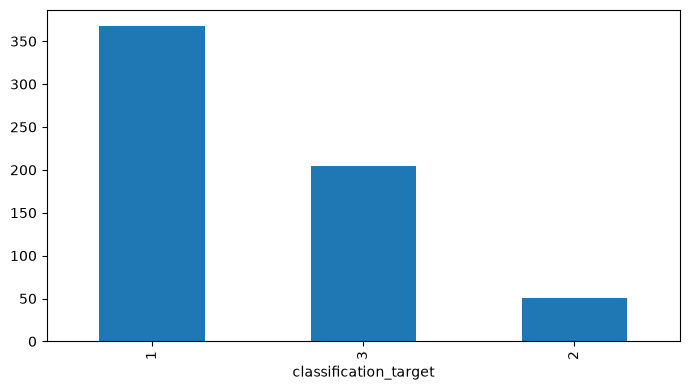

In [54]:
print("Target = class | sample per class:", train["classification_target"].value_counts().to_dict(),
      "| rows per class:", train["classification_target"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(7, 4))
train["classification_target"].value_counts().plot.bar(ax=ax)
plt.tight_layout()
plt.show()

## Reproducibility and decision record

- **Are random seeds, software versions, file names, and input/output shapes recorded?**
Seed, library versions, file name and shapes are printed in the cells of this section.

- **Are all preprocessing steps placed in a reproducible pipeline?**
The steps are scripted in a fixed order and every fitted step learns from the training data only, they are wrapped in a single scikit-learn `Pipeline` object.

- **Have I recorded unresolved data-quality concerns and the decisions made about them?**
class-2 weakness, 10 validation cases, hidden-set performance unknown.

- **Can another person explain what each row, column, feature, target, and grouping variable means?**
I am sure, that yes.

In [55]:
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("RANDOM_STATE =", RANDOM_STATE, "| input file: QSAR_challenge_train_80pct.csv and QSAR_challenge_test_20pct_NO_TARGETS.csv", train.shape, test.shape)

Python 3.11.16 | numpy 2.4.6 | pandas 2.3.3 | scikit-learn 1.9.0 | scipy 1.16.3
RANDOM_STATE = 101126 | input file: QSAR_challenge_train_80pct.csv and QSAR_challenge_test_20pct_NO_TARGETS.csv (623, 12) (156, 10)


In [56]:
# I want also check the dataset with imouted NaNs

sample_im = IterativeImputer(random_state=RANDOM_STATE)
imputation_train = X_train
imputed_train = sample_im.fit_transform(imputation_train)
imputation_train=pd.DataFrame(imputed_train, columns=imputation_train.columns)

display(imputation_train)
display(imputation_train.isna().sum())
imputation_train.describe()
display(train.isna().sum())

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O]
0,8.0,7.157,2.41,0.21,6.55,0.97,0.0,0.0,0.000000
1,1.0,0.000,1.23,0.20,2.13,0.68,0.0,1.0,1.335556
2,1.0,0.000,1.23,0.22,3.21,0.84,0.0,0.0,0.000000
3,0.0,0.000,0.00,0.34,3.48,1.67,0.0,0.0,0.000000
4,0.0,5.614,2.21,0.19,4.15,1.47,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...
618,3.0,0.000,1.49,0.18,3.70,0.69,0.0,1.0,4.000000
619,1.0,3.056,1.21,0.21,2.89,1.90,0.0,1.0,0.000000
620,0.0,6.428,2.25,0.19,3.56,2.92,0.0,1.0,15.000000
621,6.0,4.043,0.16,0.29,1.40,1.86,2.0,1.0,2.000000


nHM         0
piPC09      0
PCD         0
X2Av        0
MLOGP       0
ON1V        0
N-072       0
B02[C-N]    0
F04[C-O]    0
dtype: int64

sample_id                 0
nHM                      11
piPC09                   13
PCD                       7
X2Av                     12
MLOGP                    13
ON1V                     14
N-072                    19
B02[C-N]                  7
F04[C-O]                 16
regression_target         0
classification_target     0
dtype: int64

In [57]:
# Now we have to impute the missing values in the test set. We 
imputation_test = X_test
imputed_test = sample_im.transform(imputation_test)
imputation_test=pd.DataFrame(imputed_test, columns=imputation_test.columns)
display(imputation_test)

,nHM,piPC09,PCD,X2Av,MLOGP,ON1V,N-072,B02[C-N],F04[C-O]
0,0.0,0.000,0.450000,0.26,1.97,0.63,0.0,0.000000,0.000000
1,3.0,6.173,2.310000,0.20,5.47,1.23,0.0,0.000000,0.000000
2,2.0,0.000,0.000000,0.35,1.59,0.81,0.0,0.000000,0.000000
3,1.0,0.000,0.240000,0.38,1.67,0.41,0.0,0.000000,-0.495348
4,0.0,0.000,1.480000,0.14,1.70,0.88,0.0,1.000000,5.000000
...,...,...,...,...,...,...,...,...,...
151,4.0,6.285,2.340000,0.21,5.99,1.22,0.0,0.000000,0.000000
152,1.0,0.000,1.500000,0.18,2.84,0.91,0.0,1.000000,6.000000
153,0.0,0.000,1.510000,0.13,1.35,0.73,0.0,1.000000,5.000000
154,1.0,5.178,0.700251,0.60,5.52,4.61,0.0,0.107802,0.000000


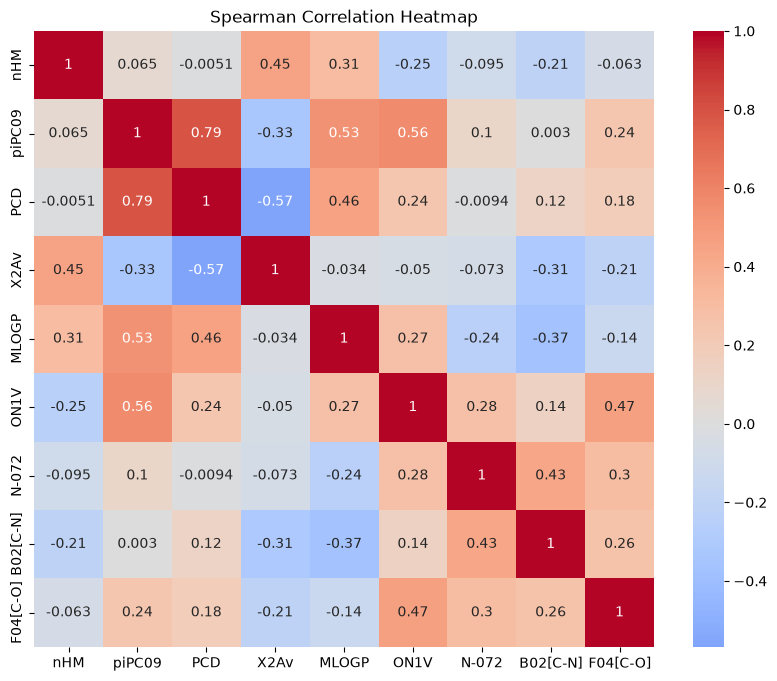

In [58]:
# Second we have to evaluate possible correlations between the features. We will use Spearman correlation for this purpose.
imputation_train.corr(method="spearman")


plt.figure(figsize=(10, 8))
sns.heatmap(imputation_train.corr(method="spearman"), annot=True, cmap="coolwarm", center=0)
plt.title("Spearman Correlation Heatmap")
plt.show()

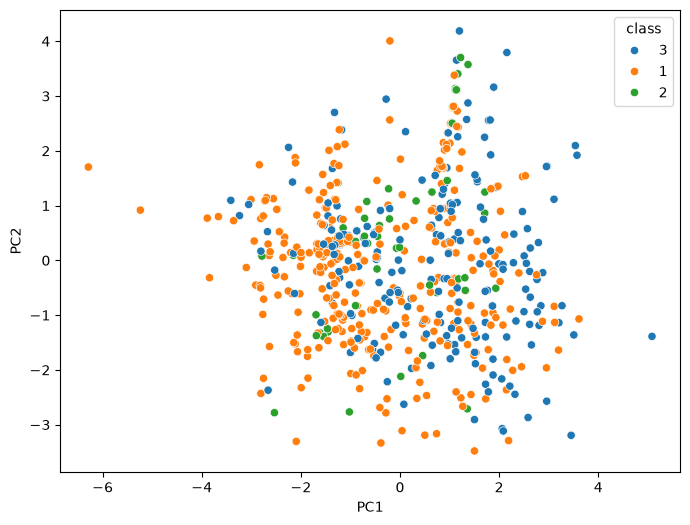

In [59]:
# I also want to check PCA plots to discover the structure of the dataset and to see if there are any clusters or patterns that can be used for classification or regression tasks
pca_data=imputation_train
scald_data=StandardScaler().fit_transform(pca_data)

pca = PCA(n_components=3, random_state=RANDOM_STATE)
coords = pca.fit_transform(scald_data)

pca_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "PC3": coords[:, 2],
    "class": train["classification_target"].astype(str).values
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue='class')
plt.show()

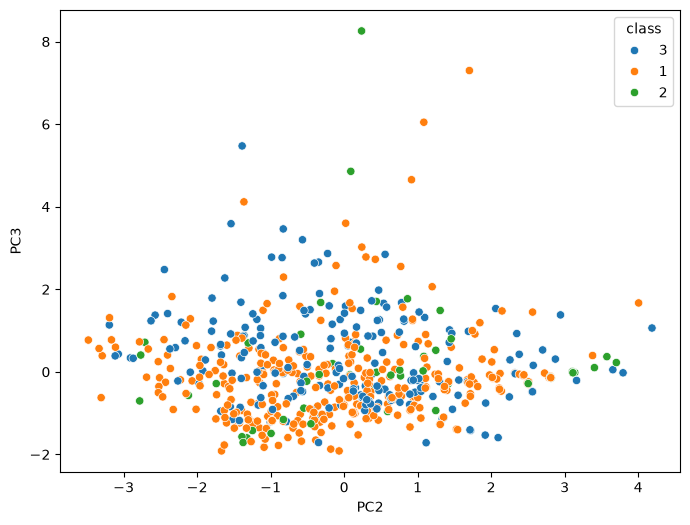

In [60]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC2", y="PC3", hue='class')
plt.show()

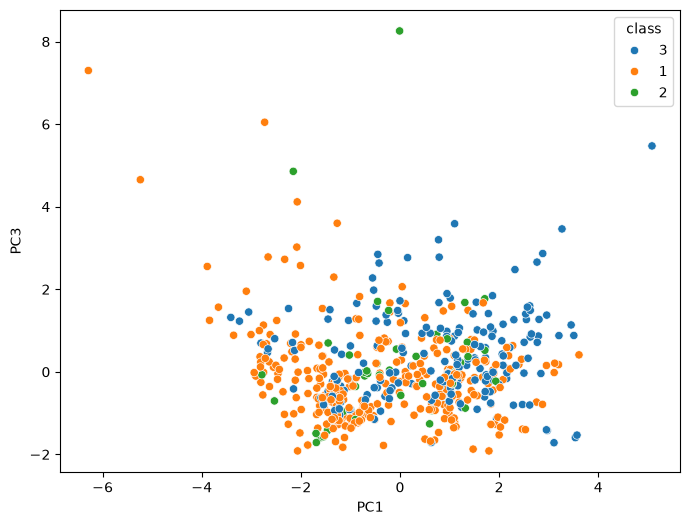

In [61]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC3", hue='class')
plt.show()

# Training

The task is to train **two models**:

1. a regression model;
2. a classification model.

### Important

Use cross-validation or an internal train/validation split **inside the 80% labelled dataset** for model selection.

## Classification

In [62]:
# I won't use previously imputed dataset cause it was just for EDA. I want to make a stratified split before imputation and training.

lo = X_train.min().to_numpy()
hi = X_train.max().to_numpy()

def make_imputer():
    return IterativeImputer(min_value=lo, max_value=hi,
                            max_iter=20, random_state=RANDOM_STATE)

In [63]:
# Stratified split of the training data into training and validation sets

idx_fit, idx_val = train_test_split(
    X_train.index, test_size=0.20,
    stratify=y_classification, random_state=RANDOM_STATE)

X_fit, X_val   = X_train.loc[idx_fit], X_train.loc[idx_val]
yc_fit, yc_val = y_classification.loc[idx_fit], y_classification.loc[idx_val]
yr_fit, yr_val = y_regression.loc[idx_fit], y_regression.loc[idx_val]

print(pd.DataFrame({"all": y_classification.value_counts(),
                    "fit": yc_fit.value_counts(),
                    "val": yc_val.value_counts()}).sort_index())

                       all  fit  val
classification_target               
1                      368  294   74
2                       51   41   10
3                      204  163   41


Since we have class imbalance here, to evaluate model performance we should use macro-F1 and balanced accuracy, and always look at per-class recall.

In [64]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

logreg = Pipeline([("imp", make_imputer()), ("scale", StandardScaler()),
                   ("model", LogisticRegression(class_weight="balanced", max_iter=3000))])
rf = Pipeline([("imp", make_imputer()),
               ("model", RandomForestClassifier(n_estimators=300,
                         class_weight="balanced_subsample", random_state=RANDOM_STATE))])

searches = {
    "logreg": GridSearchCV(logreg, {"model__C": [0.01, 0.1, 1, 10]},
                           scoring="f1_macro", cv=cv, n_jobs=-1),
    "rf": GridSearchCV(rf, {"model__min_samples_leaf": [1, 3, 5],
                            "model__max_depth": [None, 5]},
                       scoring="f1_macro", cv=cv, n_jobs=-1),
}

for name, s in searches.items():
    s.fit(X_fit, yc_fit)
    p = s.predict(X_val)
    print(f"\n{name}: {s.best_params_} | CV macro-F1 = {s.best_score_:.3f} "
          f"| val macro-F1 = {f1_score(yc_val, p, average='macro'):.3f}")
    print(classification_report(yc_val, p, digits=2))

/home/valerie/.local/share/uv/python/cpython-3.11.16-linux-x86_64-gnu/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/valerie/.local/share/uv/python/cpython-3.11.16-linux-x86_64-gnu/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/valerie/.local/share/uv/python/cpython-3.11.16-linux-x86_64-gnu/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg


logreg: {'model__C': 0.01} | CV macro-F1 = 0.459 | val macro-F1 = 0.471
              precision    recall  f1-score   support

           1       0.74      0.54      0.62        74
           2       0.20      0.60      0.30        10
           3       0.49      0.49      0.49        41

    accuracy                           0.53       125
   macro avg       0.48      0.54      0.47       125
weighted avg       0.61      0.53      0.55       125


rf: {'model__max_depth': None, 'model__min_samples_leaf': 3} | CV macro-F1 = 0.546 | val macro-F1 = 0.662
              precision    recall  f1-score   support

           1       0.74      0.77      0.75        74
           2       0.67      0.60      0.63        10
           3       0.62      0.59      0.60        41

    accuracy                           0.70       125
   macro avg       0.67      0.65      0.66       125
weighted avg       0.69      0.70      0.69       125



In [65]:
res = pd.DataFrame(searches["logreg"].cv_results_)
res[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").round(3)


,params,mean_test_score,std_test_score,rank_test_score
0,{'model__C': 0.01},0.459,0.062,1
1,{'model__C': 0.1},0.447,0.052,2
2,{'model__C': 1},0.434,0.049,3
3,{'model__C': 10},0.433,0.048,4


In [66]:
res = pd.DataFrame(searches["rf"].cv_results_)
res[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").round(3)

,params,mean_test_score,std_test_score,rank_test_score
1,"{'model__max_depth': None, 'model__min_samples...",0.546,0.068,1
3,"{'model__max_depth': 5, 'model__min_samples_le...",0.546,0.072,2
2,"{'model__max_depth': None, 'model__min_samples...",0.545,0.061,3
4,"{'model__max_depth': 5, 'model__min_samples_le...",0.545,0.073,4
0,"{'model__max_depth': None, 'model__min_samples...",0.540,0.060,5
5,"{'model__max_depth': 5, 'model__min_samples_le...",0.537,0.073,6


In [67]:
logreg_search2 = GridSearchCV(logreg, {"model__C": [0.0001, 0.001, 0.01]},
                              scoring="f1_macro", cv=cv, n_jobs=-1)
logreg_search2.fit(X_fit, yc_fit)
print(logreg_search2.best_params_, round(logreg_search2.best_score_, 3))

{'model__C': 0.0001} 0.465


In [68]:
final_cls = clone(searches["rf"].best_estimator_)
final_cls.fit(X_train, y_classification)
cls_pred_hidden = final_cls.predict(X_test)

In [69]:
pred_counts = pd.Series(cls_pred_hidden).value_counts().sort_index()
compare = pd.DataFrame({
    "hidden predicted (n)": pred_counts,
    "hidden predicted (%)": (pred_counts / len(cls_pred_hidden) * 100).round(1),
    "train true (%)": (y_classification.value_counts(normalize=True).sort_index() * 100).round(1),
})
display(compare)

proba = final_cls.predict_proba(X_test)
print(final_cls.classes_)
print(pd.Series(proba.max(axis=1)).describe().round(2))

,hidden predicted (n),hidden predicted (%),train true (%)
1,90,57.7,59.1
2,5,3.2,8.2
3,61,39.1,32.7


[1 2 3]
count    156.00
mean       0.63
std        0.13
min        0.35
25%        0.52
50%        0.61
75%        0.74
max        0.97
dtype: float64


The final model predicts the class distribution of the hidden set at 58% / 3% / 39%. Class 2 is predicted about 2.5 times less often than its training frequency (3% vs 8%), consistent with its low recall in validation. We expect performance on the hidden set to be similar to CV (macro-F1 about 0.55), with class 2 the weakest.

## Regression

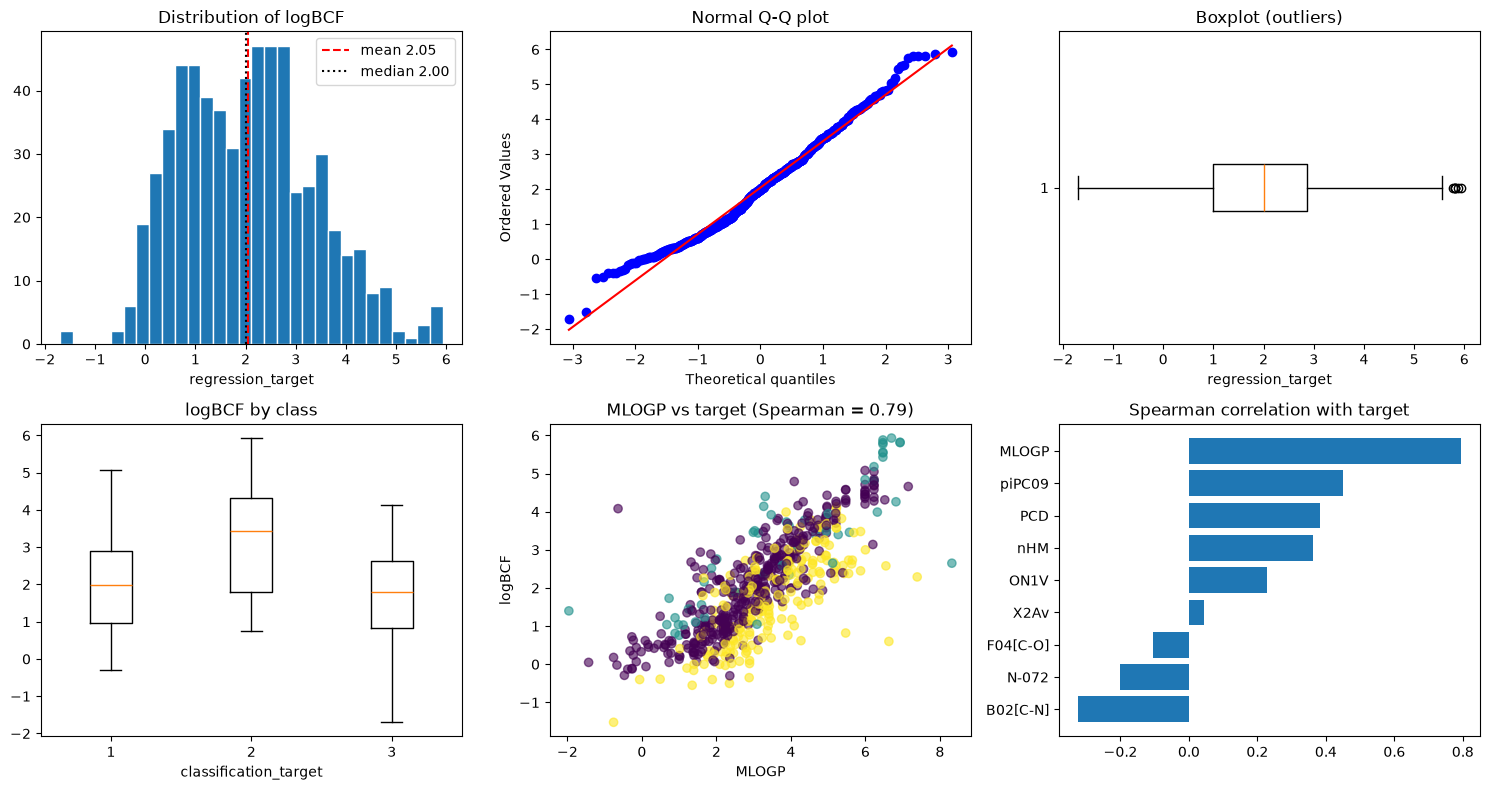

n=623  mean=2.05  median=2.00  sd=1.34  min=-1.70  max=5.93
skew=0.36  excess kurtosis=-0.25
outliers (1.5*IQR rule): 6


In [70]:
y = y_regression
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# 1) distribution
axes[0, 0].hist(y, bins=30, edgecolor="white")
axes[0, 0].axvline(y.mean(), color="r", ls="--", label=f"mean {y.mean():.2f}")
axes[0, 0].axvline(y.median(), color="k", ls=":", label=f"median {y.median():.2f}")
axes[0, 0].set_title("Distribution of logBCF"); axes[0, 0].set_xlabel("regression_target")
axes[0, 0].legend()

# 2) normality check
stats.probplot(y, dist="norm", plot=axes[0, 1]); axes[0, 1].set_title("Normal Q-Q plot")

# 3) outliers
axes[0, 2].boxplot(y, vert=False); axes[0, 2].set_title("Boxplot (outliers)")
axes[0, 2].set_xlabel("regression_target")

# 4) target by class
classes = sorted(y_classification.unique())
axes[1, 0].boxplot([y[y_classification == c] for c in classes])
axes[1, 0].set_xticklabels(classes)
axes[1, 0].set_title("logBCF by class"); axes[1, 0].set_xlabel("classification_target")

# 5) the main feature vs target
ok = X_train["MLOGP"].notna()
rho, _ = stats.spearmanr(X_train.loc[ok, "MLOGP"], y[ok])
axes[1, 1].scatter(X_train.loc[ok, "MLOGP"], y[ok], c=y_classification[ok],
                   cmap="viridis", alpha=0.6)
axes[1, 1].set_xlabel("MLOGP"); axes[1, 1].set_ylabel("logBCF")
axes[1, 1].set_title(f"MLOGP vs target (Spearman = {rho:.2f})")

# 6) all features vs target
spear = X_train.apply(lambda c: stats.spearmanr(c[c.notna()], y[c.notna()])[0]).sort_values()
axes[1, 2].barh(spear.index, spear.values)
axes[1, 2].set_title("Spearman correlation with target")

plt.tight_layout(); plt.show()

print(f"n={len(y)}  mean={y.mean():.2f}  median={y.median():.2f}  sd={y.std():.2f}  "
      f"min={y.min():.2f}  max={y.max():.2f}")
print(f"skew={stats.skew(y):.2f}  excess kurtosis={stats.kurtosis(y):.2f}")
q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
print("outliers (1.5*IQR rule):", int(((y < q1 - 1.5*iqr) | (y > q3 + 1.5*iqr)).sum()))    

Only 6 of 623 values fall outside the 1.5×IQR whiskers. That’s too few to justify removing them or switching to a robust model.
The target is continuous and roughly symmetric (skew 0.36, mean 2.05 ≈ median 2.00), so there is no equivalent of the 8% class. The class imbalance matters only for the classifier.

In [71]:
# linear baseline

cv_splits = list(RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=RANDOM_STATE).split(X_fit, yc_fit))

mlogp_idx = [feature_cols.index("MLOGP")]
baselines = {
    "mean predictor": Pipeline([("model", DummyRegressor(strategy="mean"))]),
    "linear: MLOGP only": Pipeline([("imp", make_imputer()),
        ("pick", FunctionTransformer(lambda A: A[:, mlogp_idx])),
        ("model", LinearRegression())]),
    "linear: all features": Pipeline([("imp", make_imputer()), ("scale", StandardScaler()),
        ("model", LinearRegression())]),
    "ridge: all features": Pipeline([("imp", make_imputer()), ("scale", StandardScaler()),
        ("model", Ridge(alpha=1.0))]),
}

rows = []
for name, pipe in baselines.items():
    cvres = cross_validate(pipe, X_fit, yr_fit, cv=cv_splits, n_jobs=-1,
        scoring={"rmse": "neg_root_mean_squared_error",
                 "mae": "neg_mean_absolute_error", "r2": "r2"})
    pipe.fit(X_fit, yr_fit)
    p = pipe.predict(X_val)
    rows.append({"model": name,
        "CV RMSE": -cvres["test_rmse"].mean(), "CV SD": cvres["test_rmse"].std(),
        "CV R2": cvres["test_r2"].mean(),
        "val RMSE": np.sqrt(mean_squared_error(yr_val, p)),
        "val MAE": mean_absolute_error(yr_val, p), "val R2": r2_score(yr_val, p)})

baseline_table = pd.DataFrame(rows).set_index("model").round(3)
display(baseline_table)

# which features matter (standardised coefficients of the plain linear model)
coefs = pd.Series(baselines["linear: all features"].named_steps["model"].coef_,
                  index=feature_cols).sort_values()
display(coefs.round(2))

,CV RMSE,CV SD,CV R2,val RMSE,val MAE,val R2
model,,,,,,
mean predictor,1.324,0.091,-0.009,1.367,1.128,-0.000
linear: MLOGP only,0.834,0.061,0.594,0.859,0.679,0.605
linear: all features,0.815,0.055,0.612,0.834,0.674,0.628
ridge: all features,0.814,0.055,0.612,0.834,0.674,0.628


B02[C-N]   -0.13
F04[C-O]   -0.05
N-072      -0.02
X2Av        0.02
ON1V        0.04
PCD         0.05
piPC09      0.15
nHM         0.24
MLOGP       0.77
dtype: float64

In [72]:
cv_splits = list(RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=RANDOM_STATE).split(X_fit, yc_fit))

spline = Pipeline([("imp", make_imputer()), ("scale", StandardScaler()),
                   ("spline", SplineTransformer(degree=3)), ("model", Ridge())])
poly = Pipeline([("imp", make_imputer()), ("scale", StandardScaler()),
                 ("poly", PolynomialFeatures(2, include_bias=False)),
                 ("scale2", StandardScaler()), ("model", Ridge())])
rf_reg = Pipeline([("imp", make_imputer()),
                   ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE))])

reg_searches = {
    "spline_ridge": GridSearchCV(spline, {"spline__n_knots": [3, 4, 5, 7],
                                          "model__alpha": [0.1, 1, 10, 30]},
                                 scoring="neg_root_mean_squared_error", cv=cv_splits, n_jobs=-1),
    "poly2_ridge":  GridSearchCV(poly, {"model__alpha": [1, 10, 30, 100, 300]},
                                 scoring="neg_root_mean_squared_error", cv=cv_splits, n_jobs=-1),
    "rf":           GridSearchCV(rf_reg, {"model__min_samples_leaf": [1, 3, 5, 10],
                                          "model__max_features": [0.5, 1.0]},
                                 scoring="neg_root_mean_squared_error", cv=cv_splits, n_jobs=-1),
}

for name, s in reg_searches.items():
    s.fit(X_fit, yr_fit)
    p = s.predict(X_val)
    print(f"{name:13s} {s.best_params_} | CV RMSE = {-s.best_score_:.3f} | "
          f"val RMSE = {np.sqrt(mean_squared_error(yr_val, p)):.3f}, "
          f"MAE = {mean_absolute_error(yr_val, p):.3f}, R2 = {r2_score(yr_val, p):.3f}")

spline_ridge  {'model__alpha': 0.1, 'spline__n_knots': 5} | CV RMSE = 0.758 | val RMSE = 0.824, MAE = 0.648, R2 = 0.637
poly2_ridge   {'model__alpha': 30} | CV RMSE = 0.780 | val RMSE = 0.810, MAE = 0.623, R2 = 0.649
rf            {'model__max_features': 0.5, 'model__min_samples_leaf': 5} | CV RMSE = 0.727 | val RMSE = 0.736, MAE = 0.582, R2 = 0.711


,CV RMSE,CV SD,CV R2,val RMSE,val MAE,val R2,CV RMSE vs ridge,settings
model,,,,,,,,
rf (tuned),0.727,0.036,0.693,0.736,0.582,0.711,-0.087,"{'model__max_features': 0.5, 'model__min_sampl..."
spline_ridge (tuned),0.758,0.051,0.665,0.824,0.648,0.637,-0.056,"{'model__alpha': 0.1, 'spline__n_knots': 5}"
poly2_ridge (tuned),0.780,0.058,0.645,0.810,0.623,0.649,-0.034,{'model__alpha': 30}
ridge: all features,0.814,0.055,0.612,0.834,0.674,0.628,0.000,
linear: all features,0.815,0.055,0.612,0.834,0.674,0.628,0.000,
linear: MLOGP only,0.834,0.061,0.594,0.859,0.679,0.605,0.019,
mean predictor,1.324,0.091,-0.009,1.367,1.128,-0.000,0.510,


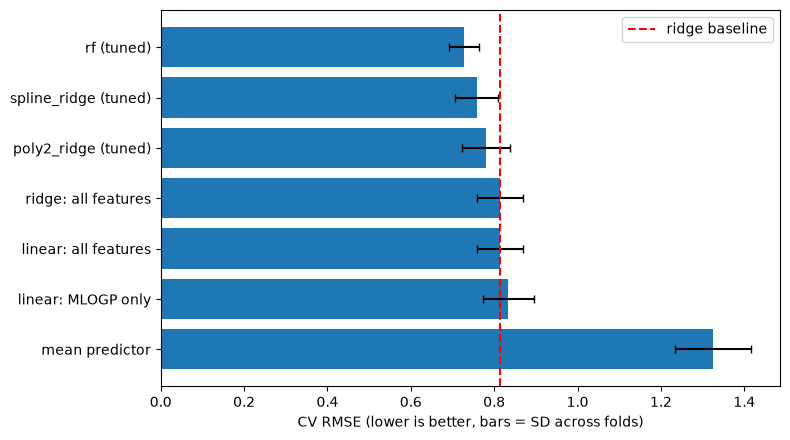

In [73]:
scoring = {"rmse": "neg_root_mean_squared_error",
           "mae": "neg_mean_absolute_error", "r2": "r2"}

# every model, baseline or tuned, goes through the same evaluation
candidates = {**baselines,
              **{f"{n} (tuned)": clone(s.best_estimator_) for n, s in reg_searches.items()}}
tuned_params = {f"{n} (tuned)": s.best_params_ for n, s in reg_searches.items()}

rows = []
for name, pipe in candidates.items():
    cvres = cross_validate(pipe, X_fit, yr_fit, cv=cv_splits, scoring=scoring, n_jobs=-1)
    pipe.fit(X_fit, yr_fit)
    p = pipe.predict(X_val)
    rows.append({"model": name,
                 "CV RMSE": -cvres["test_rmse"].mean(), "CV SD": cvres["test_rmse"].std(),
                 "CV R2": cvres["test_r2"].mean(),
                 "val RMSE": np.sqrt(mean_squared_error(yr_val, p)),
                 "val MAE": mean_absolute_error(yr_val, p),
                 "val R2": r2_score(yr_val, p)})

full_table = pd.DataFrame(rows).set_index("model")
ref = full_table.loc["ridge: all features", "CV RMSE"]
full_table["CV RMSE vs ridge"] = full_table["CV RMSE"] - ref   # negative = better than baseline
full_table = full_table.sort_values("CV RMSE").round(3)
full_table["settings"] = pd.Series(tuned_params)
display(full_table.fillna(""))

# figure for the report
t = full_table.sort_values("CV RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(t.index, t["CV RMSE"], xerr=t["CV SD"], capsize=3)
ax.axvline(ref, color="r", ls="--", label="ridge baseline")
ax.set_xlabel("CV RMSE (lower is better, bars = SD across folds)")
ax.legend(); plt.tight_layout(); plt.show()

A random forest gave the lowest cross-validated error (RMSE 0.73, R² 0.69), improving on a linear baseline (RMSE 0.81, R² 0.61) by about 0.09 log units, and this was confirmed on the held-out validation set (RMSE 0.74). Most of the linear signal comes from a single descriptor, MLOGP.

In [74]:
final_reg = clone(reg_searches["rf"].best_estimator_)   # use whichever model won by CV
final_reg.fit(X_train, y_regression)
reg_pred_hidden = final_reg.predict(X_test)

submission = pd.DataFrame({
    "sample_id": test["sample_id"],
    "regression_prediction": reg_pred_hidden,
    "classification_prediction": cls_pred_hidden,
})

# checks before saving
print(submission.shape)                 # expect (156, 3)
print(submission.isna().sum().sum())    # expect 0
print(submission["sample_id"].is_unique)
display(submission.head())

submission.to_csv("final.csv", index=False)

(156, 3)
0
True


,sample_id,regression_prediction,classification_prediction
0,78-79-5,0.826902,1
1,16606-02-3,4.149300,1
2,111-44-4,0.529696,1
3,107-05-1,0.555475,1
4,555-03-3,0.857161,1
